# 03 - Eksplorasi Dataset Kaggle (EDA)

**Dataset:** [`yaemico/judionline`](https://www.kaggle.com/datasets/yaemico/judionline) - komentar YouTube berbahasa Indonesia yang diberi label
`1` = promosi judi online, `0` = komentar normal.

Tujuan notebook ini: **memahami data sebelum melatih model** (notebook `02_training_model.ipynb`).

Isi:
1. Setup & load data
2. Gambaran umum (struktur, missing value, duplikat)
3. Memperbaiki kolom tanggal yang formatnya campur aduk
4. Distribusi label & kualitas label
5. Channel, video, dan author
6. Karakteristik teks per label (panjang, emoji, huruf "fancy", angka)
7. Kata, bigram, dan nama situs judi yang paling sering muncul
8. Pola template / spam
9. Tren waktu
10. Ringkasan temuan

> Bisa dijalankan langsung di Google Colab: *Runtime -> Run all*. Tidak perlu akun Kaggle karena dataset bersifat publik.

## 1. Setup & load data

In [1]:
# Library yang belum tersedia default di Colab
%pip install -q kagglehub emoji wordcloud nltk anyascii

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import os
from collections import Counter

import numpy as np
import pandas as pd
import kagglehub
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 120)

import matplotlib.pyplot as plt
import seaborn as sns

# Palet konsisten di semua notebook: biru = komentar normal, oranye = promosi judi
WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
WARNA_MODEL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

/home/drpoch/Devapp/claude/Tesis/tugas/NLP-AdvanceAI/Online-Gamblig-Skripsie/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import os
import re
import unicodedata
import urllib.request

import emoji
import nltk
import pandas as pd
from anyascii import anyascii
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
STOPWORDS_ID = set(stopwords.words("indonesian"))

RE_URL = re.compile(r"https?://\S+|www\.\S+")
RE_MENTION_HASHTAG = re.compile(r"[@#]\w+")
RE_YT_EMOJI = re.compile(r":([a-z0-9]+(?:-[a-z0-9]+)+):")      # emoji khusus YouTube, mis. :face-blue-smiling:
RE_RI_RUN = re.compile("[\U0001F1E6-\U0001F1FF]{3,}")           # >= 3 huruf bendera berurutan = kata, bukan bendera
RE_NON_ASCII_RUN = re.compile(r"[^\x00-\x7f]+")
RE_ASCII_PUNCT = re.compile(r"[!-/:-@\[-^`{-~]")                 # tanda baca ASCII, kecuali "_" (dipakai token)
RE_SPACED = re.compile(r"\b(?:[a-z0-9] ){3,}[a-z0-9]\b")        # "p l u t o 8 8" (minimal 4 karakter)
RE_DOLAR_HURUF = re.compile(r"(?<=[a-z])\$|\$(?=[a-z])")   # "$" menempel huruf dipakai sebagai "s"
RE_LEET = re.compile(r"^[a-z]+[0-9]+[a-z][a-z0-9]*$")           # angka di tengah huruf: m4xw1n, sl0t

# Penanda trik penyamaran. Disimpan di KOLOM TERPISAH ("sinyal"), bukan ditempel ke teks, supaya teks bersih
# tetap enak dibaca. Saat training kolom ini menjadi fitur biner di samping TF-IDF teks.
SINYAL = {
    "xxfancy": "huruf gaya: bold/italic/fullwidth, small caps, huruf-emoji (huruf dalam kotak), huruf bendera berurutan",
    "xxhomoglyph": "huruf aksara lain yang bentuknya mirip Latin (Cyrillic, Yunani, Armenia, Cherokee, ...)",
    "xxspaced": "huruf yang dipisah spasi, mis. 'P L U T O 8 8'",
    "xxdecor": "simbol non-ASCII selain emoji, mis. blok, bintang, kurung dekoratif",
    "xxleet": "leetspeak: angka di tengah huruf (m4xw1n, sl0t - teksnya TIDAK diubah) atau $ sebagai s",
    "xxinvisible": "karakter tak terlihat (zero-width space, dsb.) yang diselipkan untuk memecah kata",
}

# ---------------------------------------------------------------------------------------------
# Tabel homoglif: Unicode confusables (TR39) = pemetaan resmi karakter yang BENTUKNYA mirip.
# Hanya aksara yang lazim dipakai menyamar yang diambil; Arab, CJK, dsb. tidak dipetakan
# supaya komentar asli berbahasa/beraksara lain tidak berubah jadi huruf Latin acak.
# ---------------------------------------------------------------------------------------------
URL_CONFUSABLES = "https://www.unicode.org/Public/security/latest/confusables.txt"
AKSARA_PENYAMAR = {"CYRILLIC", "GREEK", "ARMENIAN", "CHEROKEE", "LISU", "COPTIC", "LATIN", "MODIFIER",
                   "SCRIPT", "DOUBLE-STRUCK", "BLACK-LETTER", "MATHEMATICAL", "FULLWIDTH", "ROMAN"}
AKSARA_LATIN_GAYA = {"LATIN", "MODIFIER", "SCRIPT", "DOUBLE-STRUCK", "BLACK-LETTER", "MATHEMATICAL",
                     "FULLWIDTH", "ROMAN"}
# Karakter tak terlihat yang bisa diselipkan di tengah kata: zero-width space/joiner, word joiner, BOM, soft hyphen
KARAKTER_TAK_TERLIHAT = {chr(k) for k in (0x200B, 0x200C, 0x200D, 0x2060, 0xFEFF, 0x00AD)}
# Angka gaya: angka dalam lingkaran (hitam), kurung, titik, superscript, dsb. Angka aksara lain (Arab, Devanagari)
# TIDAK diubah karena bisa jadi bagian teks asli.
VARIATION_SELECTOR = {chr(0xFE0E), chr(0xFE0F)}
AKSARA_ANGKA_GAYA = {"DINGBAT", "CIRCLED", "NEGATIVE", "PARENTHESIZED", "DIGIT", "SUPERSCRIPT", "SUBSCRIPT",
                     "DOUBLE", "FULLWIDTH", "MATHEMATICAL"}
# Pelengkap: kemiripan visual yang TIDAK ada di confusables Unicode tetapi ditemukan lewat inventaris karakter
# (mis. lambda di "lambda-lexis17", increment/delta di "$<delta>MP<delta>H"). Tambahkan di sini jika menemukan trik baru.
TAMBAHAN_VISUAL = {chr(k): v for k, v in {
    0x3BB: "a", 0x39B: "a", 0x2206: "a", 0x394: "a",                # lambda, Lambda, increment, Delta
}.items()}
HOMOGLYPH_CADANGAN = {chr(k): v for k, v in {  # dipakai jika confusables.txt gagal diunduh
    0x430: "a", 0x435: "e", 0x43E: "o", 0x440: "p", 0x441: "c", 0x443: "y",     # Cyrillic
    0x445: "x", 0x43A: "k", 0x43C: "m", 0x442: "t", 0x43D: "h", 0x432: "b",
    0x456: "i", 0x458: "j", 0x455: "s", 0x501: "d",
    0x3B1: "a", 0x3BF: "o", 0x3B5: "e", 0x3B9: "i", 0x3BA: "k", 0x3BD: "v",     # Yunani
    0x3C1: "p", 0x3C4: "t", 0x3C5: "u", 0x3C7: "x",
}.items()}


def aksara(c):
    return unicodedata.name(c, "UNKNOWN").split()[0]


def muat_confusables(path="confusables.txt"):
    peta = dict(HOMOGLYPH_CADANGAN)
    try:
        if not os.path.exists(path):
            urllib.request.urlretrieve(URL_CONFUSABLES, path)
        with open(path, encoding="utf-8-sig") as f:
            for baris in f:
                baris = baris.split("#")[0].strip()
                if not baris:
                    continue
                src, tgt = [x.strip() for x in baris.split(";")[:2]]
                src = "".join(chr(int(h, 16)) for h in src.split())
                tgt = "".join(chr(int(h, 16)) for h in tgt.split())
                if (len(src) == 1 and not src.isascii() and tgt.isascii() and tgt.isalnum()
                        and aksara(src) in AKSARA_PENYAMAR):
                    peta[src] = tgt.lower()
    except Exception as e:
        print(f"confusables.txt tidak tersedia ({e}) - memakai {len(peta)} homoglif bawaan")
    peta.update(TAMBAHAN_VISUAL)
    return peta


HOMOGLYPH = muat_confusables()
print(f"Tabel homoglif: {len(HOMOGLYPH):,} karakter")


def _emoji_ke_token(e, data):
    nama = data["en"].strip(":").lower()
    nama = re.sub(r"_?(medium-light|medium-dark|light|medium|dark)_skin_tone", "", nama)
    return " emo_" + re.sub(r"[^a-z0-9]+", "_", nama).strip("_") + " "


def proses_teks(text, remove_stopwords=True, trace=False):
    """Cleaning lengkap. Mengembalikan (teks_bersih, sinyal, karakter_tak_dikenal, langkah)."""
    sinyal, tak_dikenal, langkah = set(), [], []

    def catat(nama, t):
        if trace:
            langkah.append((nama, t))

    if not isinstance(text, str):
        return "", sinyal, tak_dikenal, langkah
    t = text
    catat("0. asli", t)

    # 1. Huruf gaya (bold, italic, fullwidth, circled) -> huruf biasa dengan NFKC
    if any(not c.isascii() and unicodedata.normalize("NFKC", c).isascii()
           and unicodedata.normalize("NFKC", c).isalnum() for c in t):
        sinyal.add("xxfancy")
    t = unicodedata.normalize("NFKC", t)
    t = RE_URL.sub(" ", t)
    t = RE_MENTION_HASHTAG.sub(" ", t).replace("_", " ")
    catat("1. NFKC, hapus URL/mention", t)

    # 2. Huruf-emoji -> huruf: huruf dalam kotak hitam (U+1F150-1F189) dan huruf bendera berurutan
    #    (>= 3, agar pasangan bendera seperti Indonesia tetap dibaca sebagai bendera)
    def ri(m):
        return "".join(chr(ord(c) - 0x1F1E6 + ord("a")) for c in m.group())
    t2 = RE_RI_RUN.sub(ri, t)
    t2 = "".join(anyascii(c) if 0x1F150 <= ord(c) <= 0x1F189 else c for c in t2)
    if t2 != t:
        sinyal.add("xxfancy")
    t = t2
    catat("2. huruf-emoji -> huruf", t)

    # 3. Emoji -> token (TIDAK dihapus): kantong uang -> emo_money_bag
    t = RE_YT_EMOJI.sub(lambda m: " emo_" + m.group(1).replace("-", "_") + " ", t)
    t = emoji.replace_emoji(t, replace=_emoji_ke_token)
    catat("3. emoji -> token", t)

    # 4. Karakter tak terlihat dibuang TANPA spasi (memecah kata: "plu<ZWSP>to" -> "pluto"),
    #    lalu homoglif -> Latin (tabel confusables) dan huruf kecil
    if any(c in KARAKTER_TAK_TERLIHAT for c in t):
        sinyal.add("xxinvisible")
    t = "".join(c for c in t if c not in KARAKTER_TAK_TERLIHAT and c not in VARIATION_SELECTOR)
    for c in set(t):
        if c in HOMOGLYPH:
            sinyal.add("xxfancy" if aksara(c) in AKSARA_LATIN_GAYA else "xxhomoglyph")
    t = "".join(HOMOGLYPH.get(c, c) for c in t).lower()
    t2 = RE_DOLAR_HURUF.sub("s", t)            # "$ampah" -> "sampah" ("$100" tidak berubah)
    if t2 != t:
        sinyal.add("xxleet")
    t = t2
    catat("4. homoglif -> Latin", t)

    # 5. Aksen dibuang (cafe' -> cafe); huruf Latin lain (small caps, o-garis) -> ASCII;
    #    angka gaya (angka dalam lingkaran hitam, dsb.) -> angka biasa; tanda baca tipografis -> tanda baca ASCII
    t = "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))
    hasil = []
    for c in t:
        if c.isascii():
            hasil.append(c)
        elif aksara(c) == "LATIN":
            if "SMALL CAPITAL" in unicodedata.name(c, "") or unicodedata.name(c, "").startswith("LATIN LETTER"):
                sinyal.add("xxfancy")
            hasil.append(anyascii(c).lower())
        elif unicodedata.digit(c, None) is not None and aksara(c) in AKSARA_ANGKA_GAYA:
            sinyal.add("xxfancy")
            hasil.append(str(unicodedata.digit(c)))
        elif 0x2010 <= ord(c) <= 0x205E and unicodedata.category(c)[0] == "P":
            hasil.append(" ")  # blok General Punctuation (kutip miring, em dash, elipsis) = tanda baca biasa
        else:
            hasil.append(c)
    t = "".join(hasil)
    catat("5. aksen, Latin lain, angka gaya", t)

    # 6. Sisa non-ASCII TIDAK dihapus diam-diam: huruf aksara lain -> xxscript_<aksara>, simbol -> xxdecor
    def sisa(m):
        run = m.group()
        tak_dikenal.extend(run)
        huruf = [c for c in run if unicodedata.category(c)[0] in "LN"]
        if huruf:
            return f" xxscript_{aksara(huruf[0]).lower().replace('-', '_')} "
        if any(unicodedata.category(c)[0] in "SP" for c in run):
            sinyal.add("xxdecor")
        return " "
    t = RE_NON_ASCII_RUN.sub(sisa, t)
    catat("6. sisa non-ASCII -> token", t)

    # 7. Tanda baca ASCII dihapus, spasi dirapikan
    t = re.sub(r"\s+", " ", RE_ASCII_PUNCT.sub(" ", t)).strip()
    catat("7. hapus tanda baca ASCII", t)

    # 8. Gabung huruf yang dispasi: "p l u t o 8 8" -> "pluto88"
    t2 = RE_SPACED.sub(lambda m: m.group().replace(" ", ""), t)
    if t2 != t:
        sinyal.add("xxspaced")
    t = t2
    catat("8. gabung huruf dispasi", t)

    # 9. Leetspeak dibiarkan apa adanya (m4xw1n tetap m4xw1n), hanya ditandai
    tokens = t.split()
    if any(RE_LEET.match(tok) for tok in tokens):
        sinyal.add("xxleet")

    # 10. Stopword Bahasa Indonesia
    if remove_stopwords:
        tokens = [tok for tok in tokens if tok not in STOPWORDS_ID]
    catat("10. hapus stopword", " ".join(tokens))

    hasil_akhir = " ".join(tokens)
    catat("11. kolom sinyal (terpisah)", " ".join(sorted(sinyal)) or "-")
    return hasil_akhir, sinyal, tak_dikenal, langkah


def clean_text(text, remove_stopwords=True):
    """Teks bersih yang enak dibaca (tanpa token sinyal). Sinyal: obfuscation_signals()."""
    return proses_teks(text, remove_stopwords)[0]


def light_clean(text):
    """Cleaning minimal untuk model karakter n-gram: huruf kecil, URL, mention. Non-ASCII DIBIARKAN."""
    text = RE_URL.sub(" ", str(text).lower())
    text = RE_MENTION_HASHTAG.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


def siapkan_input(texts):
    """Input model (training maupun prediksi): DataFrame berkolom text_clean, sinyal, text_min."""
    texts = pd.Series(texts) if not isinstance(texts, pd.Series) else texts
    hasil = texts.apply(proses_teks)
    return pd.DataFrame({
        "text_clean": hasil.str[0],
        "sinyal": hasil.str[1].apply(lambda s: " ".join(sorted(s))),
        "text_min": texts.apply(light_clean),
    }, index=texts.index)


def obfuscation_signals(text):
    return proses_teks(text)[1]


def karakter_tak_dikenal(text):
    return proses_teks(text)[2]


def tampilkan_langkah(text):
    for nama, isi in proses_teks(text, trace=True)[3]:
        print(f"{nama:30s} | {isi}")
    print()

Tabel homoglif: 1,276 karakter


In [4]:
path = kagglehub.dataset_download("yaemico/judionline")
csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
print("File:", csv_file)

df = pd.read_csv(csv_file)
df.head()

File: /home/drpoch/.cache/kagglehub/datasets/yaemico/judionline/versions/3/data_komentar_dengan_prediksi - data_komentar_dengan_prediksi(2).csv


,video_id,title,channel_name,tanggal,author,komentar,label,komentar_clean,predicted_label
0,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,0
1,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SAMPAI BINGUNG LIHAT HUMMER EV | GLAMOUR AUTO BOUTIQUE,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,suka model h2,0
2,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,0
3,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 Obell,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1
4,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Driftster‼️,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,0


## 2. Gambaran umum

| Kolom | Arti |
|---|---|
| `video_id`, `title`, `channel_name` | video asal komentar |
| `tanggal` | waktu komentar (format campur, diperbaiki di bagian 3) |
| `author` | nama akun pengomentar |
| `komentar` | teks asli komentar |
| `label` | **target**: 1 = promosi judi, 0 = normal |
| `komentar_clean` | hasil cleaning versi pembuat dataset |
| `predicted_label` | prediksi model pembuat dataset (bukan ground truth, jangan dipakai sebagai fitur) |

In [5]:
print("Ukuran data :", df.shape)
print()
df.info()

Ukuran data : (10230, 9)

<class 'pandas.DataFrame'>
RangeIndex: 10230 entries, 0 to 10229
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   video_id         10230 non-null  str  
 1   title            10230 non-null  str  
 2   channel_name     10230 non-null  str  
 3   tanggal          10230 non-null  str  
 4   author           10230 non-null  str  
 5   komentar         10230 non-null  str  
 6   label            10230 non-null  int64
 7   komentar_clean   10230 non-null  str  
 8   predicted_label  10230 non-null  int64
dtypes: int64(2), str(7)
memory usage: 2.6 MB


In [6]:
ringkas = pd.DataFrame({
    "tipe": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "nilai_unik": df.nunique(),
})
ringkas

,tipe,missing,nilai_unik
video_id,str,0,32
title,str,0,32
channel_name,str,0,18
tanggal,str,0,7289
author,str,0,9267
komentar,str,0,9001
label,int64,0,2
komentar_clean,str,0,8903
predicted_label,int64,0,2


In [7]:
print(f"Jumlah author unik  : {df['author'].nunique():,}")
print(f"Jumlah channel unik : {df['channel_name'].nunique():,}")
print(f"Jumlah video unik   : {df['video_id'].nunique():,}")
print(f"Baris duplikat penuh            : {df.duplicated().sum():,}")
print(f"Duplikat teks komentar (persis) : {df['komentar'].duplicated().sum():,}")

Jumlah author unik  : 9,267
Jumlah channel unik : 18
Jumlah video unik   : 32
Baris duplikat penuh            : 0
Duplikat teks komentar (persis) : 1,229


## 3. Memperbaiki kolom `tanggal`

Kolom `tanggal` berisi dua format sekaligus:
- unix timestamp (milidetik/mikrodetik) yang rusak karena diberi titik ribuan, mis. `1.745.412.234.123.970`
- string ISO, mis. `2025-04-30 09:01:02+00:00`

Untuk format pertama, titik dibuang lalu 10 digit pertama dibaca sebagai detik unix.

In [8]:
def parse_tanggal(s):
    s = str(s).strip()
    if re.fullmatch(r"[\d.]+", s):
        digits = s.replace(".", "")
        return pd.to_datetime(int(digits[:10]), unit="s", utc=True)
    return pd.to_datetime(s, utc=True, errors="coerce")

df["format_tanggal"] = np.where(df["tanggal"].str.fullmatch(r"[\d.]+"), "unix bertitik", "ISO")
df["waktu"] = df["tanggal"].apply(parse_tanggal)

print(df["format_tanggal"].value_counts(), "\n")
print("Gagal di-parse :", df["waktu"].isna().sum())
print("Rentang waktu  :", df["waktu"].min(), "s/d", df["waktu"].max())
df[["tanggal", "format_tanggal", "waktu"]].sample(5, random_state=0)

format_tanggal
unix bertitik    7272
ISO              2958
Name: count, dtype: int64 

Gagal di-parse : 0
Rentang waktu  : 2025-02-06 07:05:31+00:00 s/d 2025-05-04 13:36:57+00:00


,tanggal,format_tanggal,waktu
6125,1.745.387.030.603.970,unix bertitik,2025-04-23 05:43:50+00:00
8745,173.882.554.098.906,unix bertitik,2025-02-06 07:05:40+00:00
39,1.739.946.323.623.560,unix bertitik,2025-02-19 06:25:23+00:00
5105,1.739.947.013.183.460,unix bertitik,2025-02-19 06:36:53+00:00
3380,2025-04-30 09:01:02+00:00,ISO,2025-04-30 09:01:02+00:00


## 4. Distribusi label & kualitas label

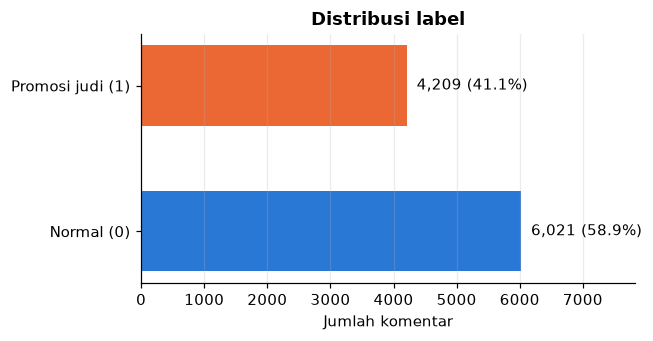

In [9]:
jumlah = df["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh([NAMA_LABEL[i] for i in jumlah.index], jumlah.values,
               color=[WARNA_LABEL[i] for i in jumlah.index], height=0.55)
for b, v in zip(bars, jumlah.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f"  {v:,} ({v / len(df):.1%})", va="center")
ax.set_xlabel("Jumlah komentar")
ax.set_title("Distribusi label")
ax.set_xlim(0, jumlah.max() * 1.3)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Data **tidak seimbang ringan** (~59% : 41%). Ini akan ditangani saat training (undersampling pada data latih saja).

Dataset juga menyertakan `predicted_label` dari model pembuatnya. Membandingkannya dengan `label` memberi gambaran seberapa sulit tugas ini.

Kesesuaian label vs predicted_label: 99.16%


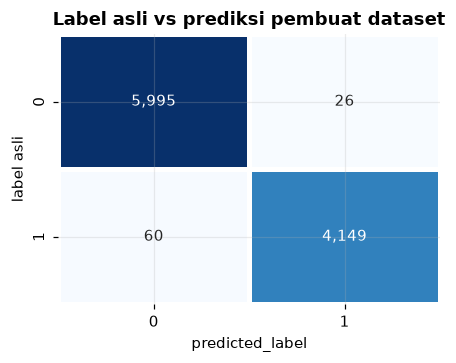

,komentar,label,predicted_label
0,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆𝐈𝟖𝟖.,1,0
426,@ jadilah top mantap is the best :face-blue-smiling:,0,1
481,kapan lagi wehde 2 juta modal 50k? ⭐ A L E X I S 1 7 ⭐ doang kayak nya wkwkwk,1,0
586,"Gue buka YouTube, yang direkomendasiin isinya PULAUWIN semua.",1,0
611,Layanannya di 𝘼X𝙇𝟩𝟽7juga oke banget! Gak ada masalah sama sekali!,1,0
655,meuni gacoor pisan iyeu ꗥ𝙈𝘼𝙉𝙐𝙏88ꗥ,1,0
898,Bener benar gelapppppp,0,1
970,ngopi muter digaruda hoki manteeb bat,1,0
1176,"Best, ini gokil banget sih🔥👍🏻",0,1
1465,puma speedcat bikin ngiler,0,1


In [10]:
ct = pd.crosstab(df["label"], df["predicted_label"], rownames=["label asli"], colnames=["predicted_label"])
print(f"Kesesuaian label vs predicted_label: {(df['label'] == df['predicted_label']).mean():.2%}")

fig, ax = plt.subplots(figsize=(4.2, 3.4))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
ax.set_title("Label asli vs prediksi pembuat dataset")
plt.tight_layout()
plt.show()

df.loc[df["label"] != df["predicted_label"], ["komentar", "label", "predicted_label"]].head(10)

## 5. Channel, video, dan author

In [11]:
per_channel = (df.groupby("channel_name")
                 .agg(komentar=("label", "size"), promosi=("label", "sum"), video=("video_id", "nunique"))
                 .assign(persen_promosi=lambda d: d["promosi"] / d["komentar"] * 100)
                 .sort_values("komentar", ascending=False))
per_channel.head(15)

,komentar,promosi,video,persen_promosi
channel_name,,,,
Garasi Drift,1951,588,4,30.138391
GadgetIn,1455,615,2,42.268041
Narasi Newsroom,1453,0,1,0.000000
Fitra Eri,1180,1036,4,87.796610
Pandji Pragiwaksono,837,130,1,15.531661
Motomobi,806,714,4,88.585608
Wakil Presiden Republik Indonesia,804,0,1,0.000000
Karbida FC,460,268,1,58.260870
Om Mobi,408,397,2,97.303922


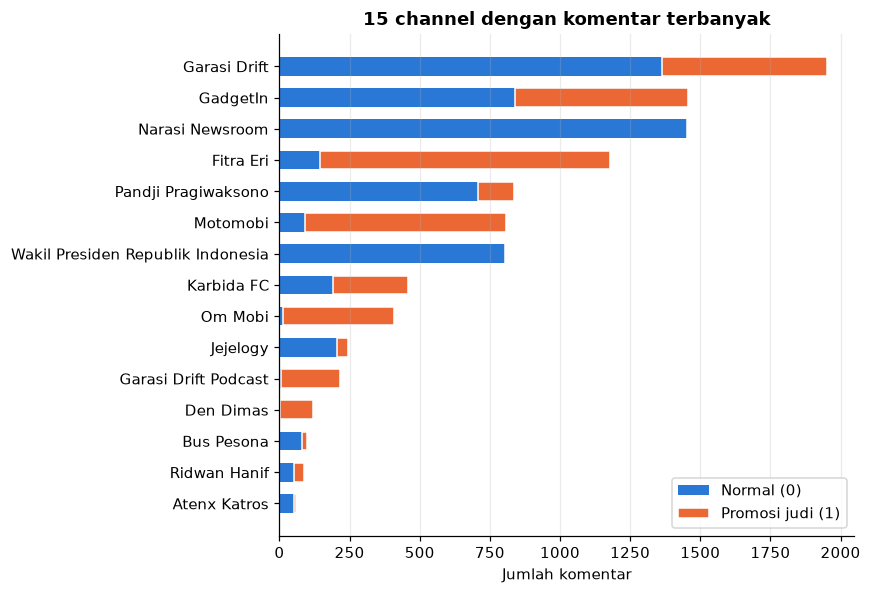

In [12]:
top = per_channel.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["komentar"] - top["promosi"], color=WARNA_LABEL[0], label=NAMA_LABEL[0], height=0.6)
ax.barh(top.index, top["promosi"], left=top["komentar"] - top["promosi"], color=WARNA_LABEL[1],
        label=NAMA_LABEL[1], height=0.6, edgecolor="white", linewidth=1)
ax.set_xlabel("Jumlah komentar")
ax.set_title("15 channel dengan komentar terbanyak")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [13]:
per_author = df.groupby("author").agg(komentar=("label", "size"), promosi=("label", "sum"))
print(f"Author yang menulis >1 komentar promosi : {(per_author['promosi'] > 1).sum():,}")
print(f"Author yang menulis promosi DAN normal  : {((per_author['promosi'] > 0) & (per_author['promosi'] < per_author['komentar'])).sum():,}")

# Handle YouTube otomatis biasanya berakhiran '-xxx' (3 karakter acak), sering dipakai akun bot
df["author_pola_otomatis"] = df["author"].str.contains(r"-[a-z0-9]{3}$", regex=True)
print()
print("Proporsi author berpola handle otomatis per label:")
print(df.groupby("label")["author_pola_otomatis"].mean().rename(NAMA_LABEL).map("{:.1%}".format))
per_author.sort_values("promosi", ascending=False).head(10)

Author yang menulis >1 komentar promosi : 181
Author yang menulis promosi DAN normal  : 12

Proporsi author berpola handle otomatis per label:
label
Normal (0)           5.9%
Promosi judi (1)    53.8%
Name: author_pola_otomatis, dtype: str


,komentar,promosi
author,,
MotorRacing-v8m,5,5
alarconJgillen-p9f,3,3
Rsabadoondi-w5c,3,3
aalambhatibhati3264,3,3
latuponogaluh,3,3
KancutBadak-h4v,3,3
GuillaumeMadara-v7q,3,3
ProgrammerJcui-o9o,3,3
PitcherS-n4h,3,3


## 6. Karakteristik teks per label

Fitur sederhana yang dihitung dari teks **asli** (`komentar`):
- `n_char`, `n_kata` - panjang komentar
- `n_emoji` - jumlah emoji
- `n_fancy` - jumlah huruf "fancy" (mis. huruf Mathematical Bold) yang berubah setelah normalisasi NFKC; trik umum untuk menghindari filter kata
- `ada_brand` - ada token huruf+angka seperti `pluto88`, `alexis17` (pola nama situs judi)

In [14]:
def n_fancy(text):
    return sum(1 for c in str(text) if ord(c) > 127 and unicodedata.normalize("NFKC", c) != c)

hasil_clean = df["komentar"].apply(proses_teks)     # (teks_bersih, sinyal, sisa_non_ascii, langkah)
df["komentar_bersih"] = hasil_clean.str[0]
df["sinyal"] = hasil_clean.str[1]
df["sisa_non_ascii"] = hasil_clean.str[2]
df["n_char"] = df["komentar"].str.len()
df["n_kata"] = df["komentar"].str.split().str.len()
df["n_emoji"] = df["komentar"].apply(emoji.emoji_count)
df["n_fancy"] = df["komentar"].apply(n_fancy)
df["ada_brand"] = df["komentar_bersih"].str.contains(r"\b[a-z]+\d{2,}\b", regex=True)

fitur = ["n_char", "n_kata", "n_emoji", "n_fancy", "ada_brand"]
df.groupby("label")[fitur].mean().rename(index=NAMA_LABEL).round(2)

,n_char,n_kata,n_emoji,n_fancy,ada_brand
label,,,,,
Normal (0),36.13,6.17,0.56,0.16,0.01
Promosi judi (1),45.94,8.10,0.18,2.57,0.67


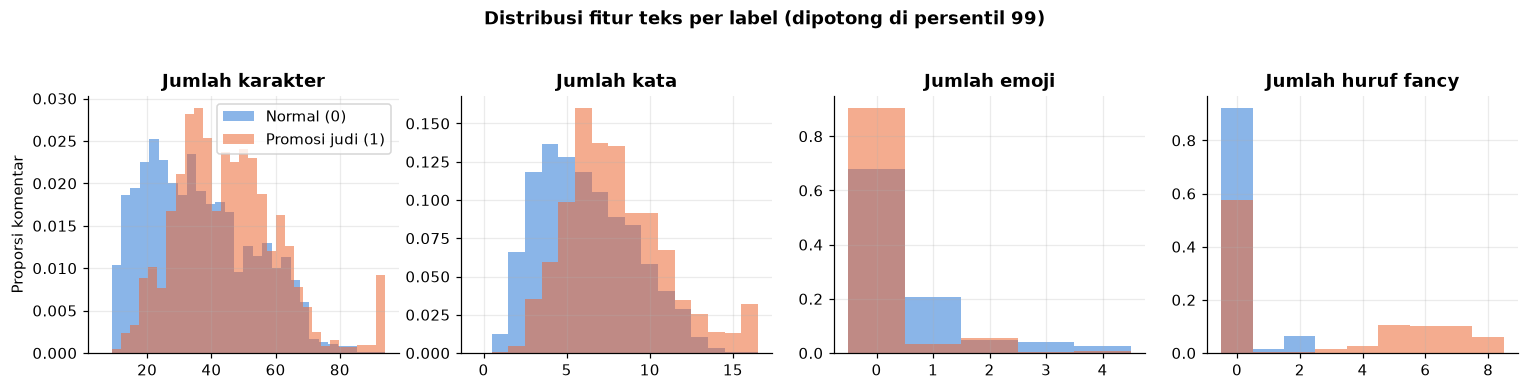

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (kol, judul) in zip(axes, [("n_char", "Jumlah karakter"), ("n_kata", "Jumlah kata"),
                                    ("n_emoji", "Jumlah emoji"), ("n_fancy", "Jumlah huruf fancy")]):
    batas = int(df[kol].quantile(0.99))
    bins = np.arange(0, batas + 2) - 0.5 if batas <= 30 else 30
    for lab in [0, 1]:
        data = df.loc[df["label"] == lab, kol].clip(upper=batas)
        # density=True -> proporsi, supaya kelas yang lebih besar tidak terlihat dominan
        ax.hist(data, bins=bins, density=True, alpha=0.55, color=WARNA_LABEL[lab], label=NAMA_LABEL[lab])
    ax.set_title(judul)
axes[0].set_ylabel("Proporsi komentar")
axes[0].legend()
plt.suptitle("Distribusi fitur teks per label (dipotong di persentil 99)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

In [16]:
print("Contoh efek normalisasi NFKC pada komentar promosi ber-huruf fancy:\n")
contoh = df[(df["label"] == 1) & (df["n_fancy"] > 0)].sample(5, random_state=1)
for _, r in contoh.iterrows():
    print("ASLI  :", r["komentar"])
    print("BERSIH:", r["komentar_bersih"])
    print()

Contoh efek normalisasi NFKC pada komentar promosi ber-huruf fancy:

ASLI  : orang kantor udh join 𝘼𝙇𝙀𝙓𝙄𝙎17
BERSIH: orang kantor udh join alexis17

ASLI  : Gak sabar buat main lagi di 𝘈𝐺𝐔𝑆𝐓𝑂𝙏𝘖, karena rezeki datang tak terduga!
BERSIH: gak sabar main agustoto rezeki terduga

ASLI  : aer𝘖 88 menawarkan pendekatan berbeda keterlibatan daring .
BERSIH: aero 88 menawarkan pendekatan berbeda keterlibatan daring

ASLI  : Salam ⭐𝐒𝐆𝐈𝟖𝟖! gampang Jepe ,Sehat selalu buat semuanya
BERSIH: salam emo_star sgi88 gampang jepe sehat

ASLI  : depo , mekswin 𝘋 𝐸 𝙒 𝐴 𝐷 о 𝐑 a
BERSIH: depo mekswin dewadora



## 7. Kata, bigram, dan nama situs judi

Teks dibersihkan dengan fungsi `clean_text` yang **sama persis** dengan yang dipakai di notebook 01 (scraping) dan 02 (training).

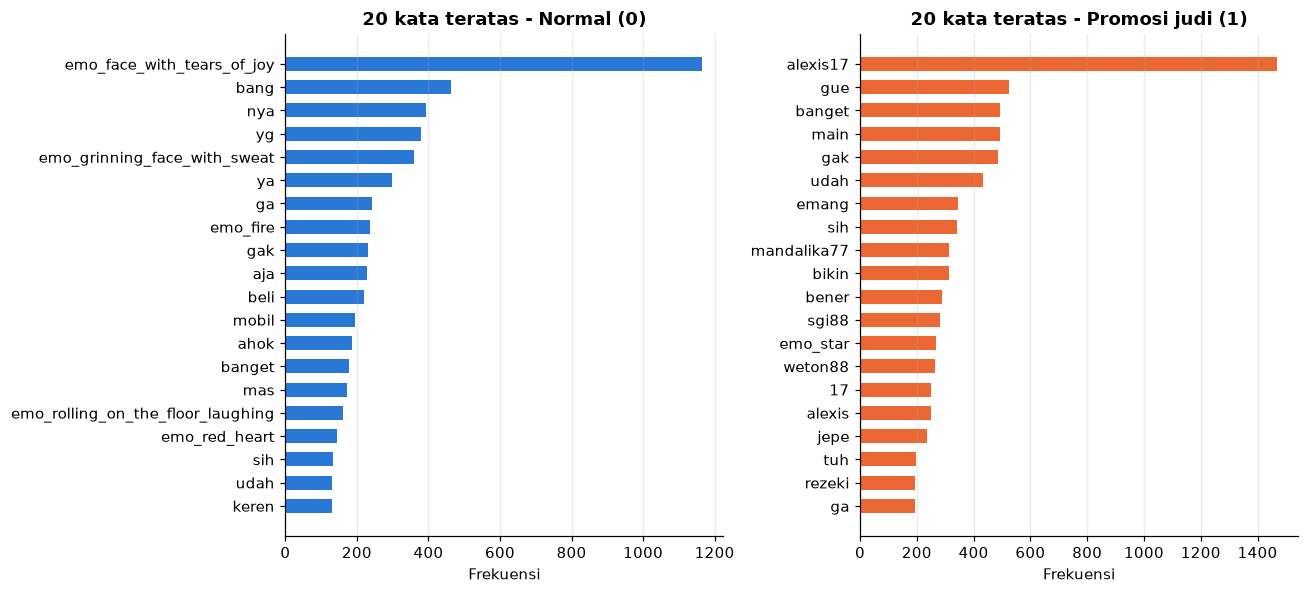

In [17]:
def top_tokens(series, n=20):
    # token sinyal (xx...) tidak ikut dihitung; token emoji (emo_...) ikut
    return Counter(t for t in " ".join(series).split() if not t.startswith("xx")).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, lab in zip(axes, [0, 1]):
    kata, frek = zip(*top_tokens(df.loc[df["label"] == lab, "komentar_bersih"]))
    ax.barh(kata[::-1], frek[::-1], color=WARNA_LABEL[lab], height=0.6)
    ax.set_title(f"20 kata teratas - {NAMA_LABEL[lab]}")
    ax.set_xlabel("Frekuensi")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [18]:
def top_bigram(series, n=15):
    cv = CountVectorizer(ngram_range=(2, 2), min_df=3)
    X = cv.fit_transform(series)
    frek = np.asarray(X.sum(axis=0)).ravel()
    idx = frek.argsort()[::-1][:n]
    return pd.Series(frek[idx], index=cv.get_feature_names_out()[idx])

pd.concat({NAMA_LABEL[lab]: top_bigram(df.loc[df["label"] == lab, "komentar_bersih"]).reset_index()
           .set_axis(["bigram", "frekuensi"], axis=1) for lab in [0, 1]}, axis=1)

Normal (0)  \
                                                                 bigram   
0                 emo_face_with_tears_of_joy emo_face_with_tears_of_joy   
1                                                     emo_fire emo_fire   
2             emo_grinning_face_with_sweat emo_grinning_face_with_sweat   
3                                           emo_red_heart emo_red_heart   
4   emo_rolling_on_the_floor_laughing emo_rolling_on_the_floor_laughing   
5                                     emo_party_popper emo_party_popper   
6                         emo_loudly_crying_face emo_loudly_crying_face   
7                                                           modif motor   
8                                           emo_thumbs_up emo_thumbs_up   
9                                 emo_clapping_hands emo_clapping_hands   
10                                      emo_crying_face emo_crying_face   
11                                                        langsung beli   
12                                                             mas dipo   
13                                                         garasi drift   
14                                                         keren banget   

             Promosi judi (1)            
   frekuensi           bigram frekuensi  
0        414         gue udah       155  
1        132    main alexis17       150  
2         94     alexis17 tuh       145  
3         67        emang gak       141  
4         67        alexis 17       139  
5         58      bener bener       126  
6         53  alexis emo_star       109  
7         42      emo_star 17       109  
8         33      17 emo_star       109  
9         33     alexis17 gue       106  
10        26      tujuh tujuh       102  
11        25  bilang alexis17        85  
12        24    join alexis17        82  
13        24         gue rela        74  
14        23          gue sih        70

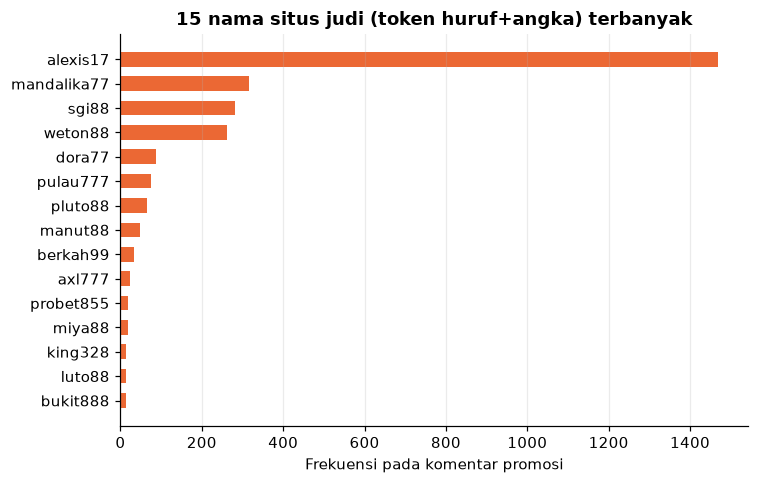

Komentar promosi yang memuat token brand : 67.1%
Komentar normal yang memuat token brand  : 1.0%


In [19]:
# Token huruf+angka (mis. pluto88, alexis17) adalah pola khas nama situs judi
brand = Counter(t for teks in df.loc[df["label"] == 1, "komentar_bersih"]
                for t in teks.split() if re.fullmatch(r"[a-z]+\d{2,}", t))
top_brand = pd.Series(dict(brand.most_common(15)))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_brand.index[::-1], top_brand.values[::-1], color=WARNA_LABEL[1], height=0.6)
ax.set_title("15 nama situs judi (token huruf+angka) terbanyak")
ax.set_xlabel("Frekuensi pada komentar promosi")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Komentar promosi yang memuat token brand : {df.loc[df['label'] == 1, 'ada_brand'].mean():.1%}")
print(f"Komentar normal yang memuat token brand  : {df.loc[df['label'] == 0, 'ada_brand'].mean():.1%}")

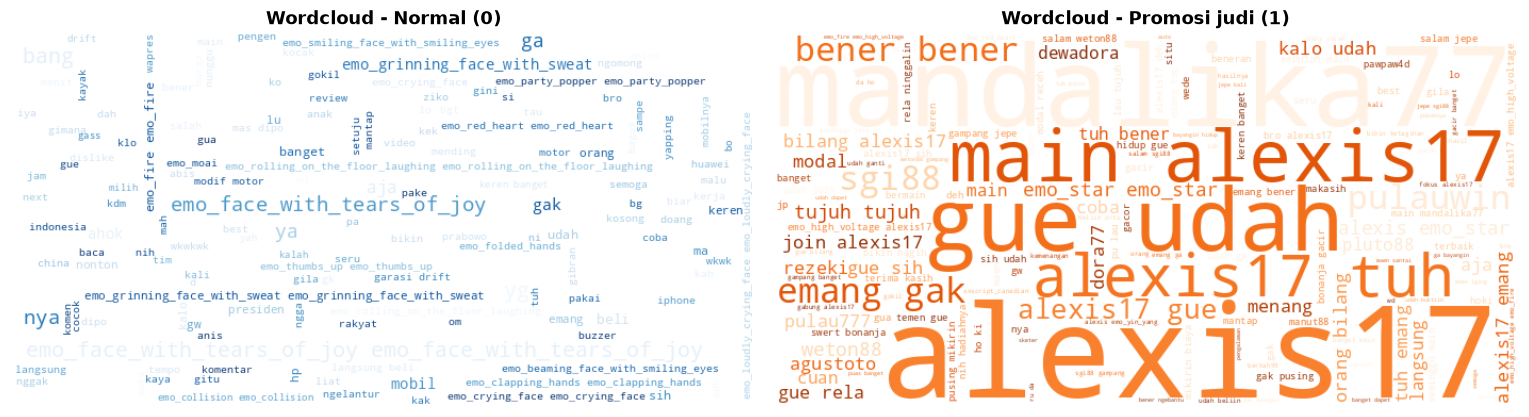

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, lab, cmap in zip(axes, [0, 1], ["Blues", "Oranges"]):
    teks = " ".join(df.loc[df["label"] == lab, "komentar_bersih"])
    wc = WordCloud(width=700, height=350, background_color="white", colormap=cmap,
                   max_words=150, random_state=42).generate(teks)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Wordcloud - {NAMA_LABEL[lab]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Emoji, aksara lain, dan trik penyamaran

Cleaning v2 **tidak membuang** non-ASCII begitu saja:
- emoji menjadi token `emo_<nama>` (mis. `emo_money_bag`)
- huruf aksara lain yang tidak mirip Latin menjadi `xxscript_<aksara>`
- trik penyamaran dicatat di kolom `sinyal` terpisah (`xxfancy`, `xxhomoglyph`, `xxspaced`, `xxdecor`, `xxleet`, `xxinvisible`)

Bagian ini melihat seberapa berbeda pemakaiannya antara komentar normal dan promosi.

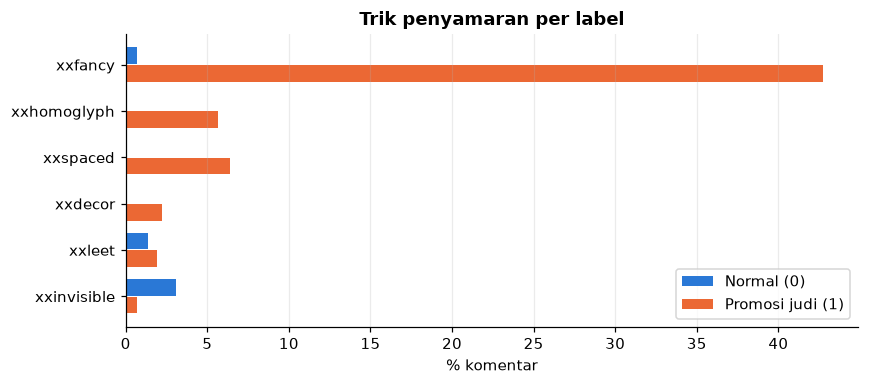

,Normal (0),Promosi judi (1)
xxfancy,0.7,42.7
xxhomoglyph,0.0,5.7
xxspaced,0.0,6.4
xxdecor,0.0,2.2
xxleet,1.4,1.9
xxinvisible,3.1,0.7


In [21]:
prev = pd.DataFrame({NAMA_LABEL[lab]: {k: df.loc[df["label"] == lab, "sinyal"].apply(lambda s: k in s).mean() * 100
                                       for k in SINYAL} for lab in [0, 1]})

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(prev))
for i, lab in enumerate([0, 1]):
    ax.barh(y + (i - 0.5) * 0.38, prev[NAMA_LABEL[lab]], height=0.36, color=WARNA_LABEL[lab], label=NAMA_LABEL[lab])
ax.set_yticks(y, prev.index)
ax.invert_yaxis()
ax.set_xlabel("% komentar")
ax.set_title("Trik penyamaran per label")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
prev.round(1)

In [22]:
def top_prefix(series, prefix, n=10):
    return Counter(t for s in series for t in s.split() if t.startswith(prefix)).most_common(n)

pd.concat({NAMA_LABEL[lab]: pd.DataFrame(top_prefix(df.loc[df["label"] == lab, "komentar_bersih"], "emo_"),
                                         columns=["token emoji", "jumlah"]) for lab in [0, 1]}, axis=1)

Normal (0)         \
                          token emoji jumlah   
0          emo_face_with_tears_of_joy   1166   
1        emo_grinning_face_with_sweat    360   
2                            emo_fire    237   
3   emo_rolling_on_the_floor_laughing    162   
4                       emo_red_heart    144   
5                    emo_party_popper    129   
6                     emo_crying_face    122   
7              emo_loudly_crying_face    108   
8  emo_smiling_face_with_smiling_eyes     93   
9                       emo_thumbs_up     80   

                     Promosi judi (1)         
                          token emoji jumlah  
0                            emo_star    267  
1                    emo_high_voltage    116  
2                            emo_fire     69  
3                        emo_yin_yang     33  
4                       emo_red_heart     30  
5                 emo_triangular_flag     26  
6                emo_revolving_hearts     24  
7                    emo_victory_hand     12  
8                    emo_party_popper     10  
9  emo_beaming_face_with_smiling_eyes      9

In [23]:
# Inventaris karakter non-ASCII yang TIDAK bisa dipetakan ke huruf Latin (dijadikan xxscript_/xxdecor).
# Daftar ini dipakai untuk menemukan trik baru yang perlu ditambahkan ke pemetaan.
sisa = Counter(c for s in df["sisa_non_ascii"] for c in s)
pd.DataFrame([(c, f"U+{ord(c):04X}", unicodedata.name(c, "?"), n) for c, n in sisa.most_common(15)],
             columns=["karakter", "kode", "nama Unicode", "jumlah"])

,karakter,kode,nama Unicode,jumlah
0,░,U+2591,LIGHT SHADE,82
1,✦,U+2726,BLACK FOUR POINTED STAR,44
2,═,U+2550,BOX DRAWINGS DOUBLE HORIZONTAL,42
3,─,U+2500,BOX DRAWINGS LIGHT HORIZONTAL,34
4,я,U+044F,CYRILLIC SMALL LETTER YA,30
5,▒,U+2592,MEDIUM SHADE,30
6,▓,U+2593,DARK SHADE,20
7,ᗩ,U+15E9,CANADIAN SYLLABICS CARRIER PO,19
8,ᗷ,U+15F7,CANADIAN SYLLABICS CARRIER KHE,19
9,★,U+2605,BLACK STAR,18


## 8. Pola template / spam

Bot promosi biasanya memakai **kalimat template** yang sama dan hanya mengganti nama situs.
Untuk melihatnya, token brand diganti `<brand>` lalu dihitung kalimat yang berulang.

In [24]:
df["template"] = df["komentar_bersih"].str.replace(r"\b[a-z]+\d{2,}\b", "<brand>", regex=True)

dup = df.groupby("label").agg(
    total=("template", "size"),
    teks_unik=("komentar_bersih", "nunique"),
    template_unik=("template", "nunique"),
).rename(index=NAMA_LABEL)
dup["persen_template_berulang"] = (1 - dup["template_unik"] / dup["total"]) * 100
display(dup.round(1))

df[df["label"] == 1]["template"].value_counts().head(10).to_frame("jumlah")

,total,teks_unik,template_unik,persen_template_berulang
label,,,,
Normal (0),6021,5971,5971,0.8
Promosi judi (1),4209,2714,2539,39.7


,jumlah
template,
semangat bosqu terbaik <brand>,16
auto jepey <brand>,14
kerennn contentnya bang cari situs <brand>,13
sukaaa bangettt <brand>,13
<brand> bikin maxwin gampang,12
ok min <brand>,12
gw demen gas <brand> wkwkwkww seru sering2 sih mah,12
berkah rezeki berkat <brand> puji syukur,11
cakep kali <brand> bravo,11


## 9. Tren waktu

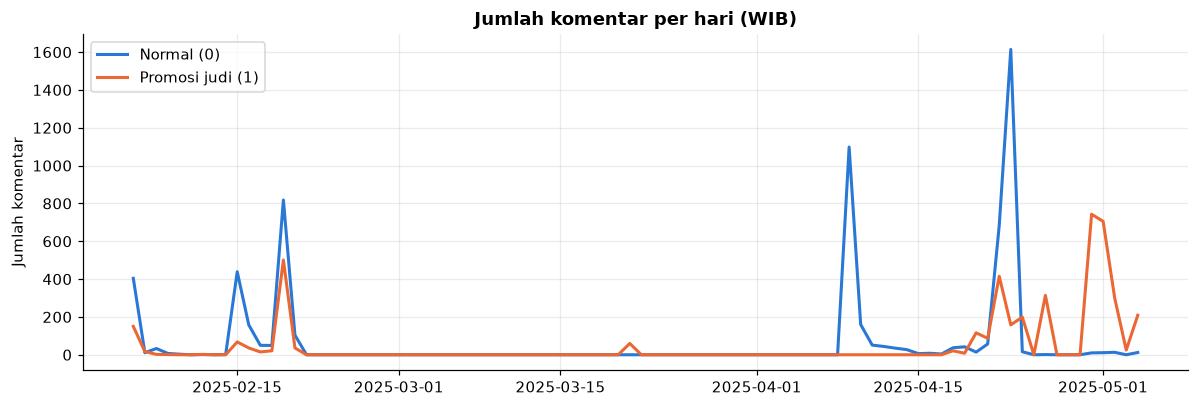

In [25]:
harian = (df.dropna(subset=["waktu"])
            .assign(tanggal_saja=lambda d: d["waktu"].dt.tz_convert("Asia/Jakarta").dt.date)
            .groupby(["tanggal_saja", "label"]).size().unstack(fill_value=0))
harian.index = pd.to_datetime(harian.index)
# Isi hari tanpa komentar dengan 0 agar garis tidak "melompati" tanggal kosong
harian = harian.reindex(pd.date_range(harian.index.min(), harian.index.max(), freq="D"), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.8))
for lab in [0, 1]:
    if lab in harian:
        ax.plot(harian.index, harian[lab], color=WARNA_LABEL[lab], lw=2, label=NAMA_LABEL[lab])
ax.set_title("Jumlah komentar per hari (WIB)")
ax.set_ylabel("Jumlah komentar")
ax.legend()
plt.tight_layout()
plt.show()

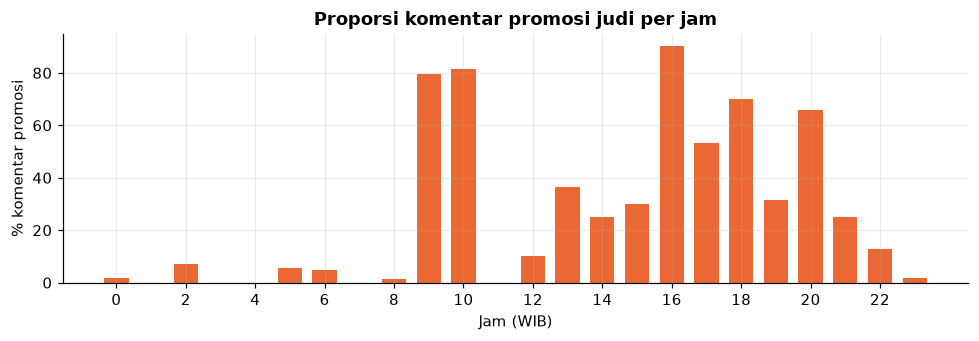

In [26]:
jam = df.dropna(subset=["waktu"]).assign(jam=lambda d: d["waktu"].dt.tz_convert("Asia/Jakarta").dt.hour)
proporsi_jam = jam.groupby("jam")["label"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(proporsi_jam.index, proporsi_jam.values, color=WARNA_LABEL[1], width=0.7)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("% komentar promosi")
ax.set_title("Proporsi komentar promosi judi per jam")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

## 10. Ringkasan temuan

In [27]:
p, n = df[df["label"] == 1], df[df["label"] == 0]
print(f"- {len(df):,} komentar dari {df['video_id'].nunique()} video / {df['channel_name'].nunique()} channel; "
      f"{df['label'].mean():.1%} berlabel promosi judi.")
print(f"- Tidak ada missing value; kolom tanggal perlu diparse ulang karena 2 format bercampur.")
print(f"- Kesesuaian label vs predicted_label bawaan dataset: {(df['label'] == df['predicted_label']).mean():.1%}.")
print(f"- Komentar promosi rata-rata {p['n_kata'].mean():.1f} kata vs normal {n['n_kata'].mean():.1f} kata.")
print(f"- Huruf fancy muncul di {(p['n_fancy'] > 0).mean():.1%} komentar promosi vs {(n['n_fancy'] > 0).mean():.1%} komentar normal.")
print(f"- Token brand (huruf+angka) ada di {p['ada_brand'].mean():.1%} komentar promosi vs {n['ada_brand'].mean():.1%} komentar normal.")
print(f"- Brand paling sering: {', '.join(top_brand.index[:5])}.")

- 10,230 komentar dari 32 video / 18 channel; 41.1% berlabel promosi judi.
- Tidak ada missing value; kolom tanggal perlu diparse ulang karena 2 format bercampur.
- Kesesuaian label vs predicted_label bawaan dataset: 99.2%.
- Komentar promosi rata-rata 8.1 kata vs normal 6.2 kata.
- Huruf fancy muncul di 42.3% komentar promosi vs 7.9% komentar normal.
- Token brand (huruf+angka) ada di 67.1% komentar promosi vs 1.0% komentar normal.
- Brand paling sering: alexis17, mandalika77, sgi88, weton88, dora77.


**Implikasi untuk training (notebook 02):**
1. Non-ASCII **jangan dibuang dan jangan dipakai mentah**: normalisasi (NFKC, tabel homoglif Unicode, huruf-emoji) agar
   `PLUTO88` versi huruf fancy terbaca sebagai `pluto88`, lalu simpan triknya di kolom sinyal terpisah. Emoji dijadikan token.
2. Kolom `predicted_label` tidak boleh dipakai sebagai fitur (bocoran jawaban).
3. Banyak kalimat template yang berulang -> lakukan **deduplikasi sebelum split** agar kalimat yang sama tidak muncul di data latih dan data uji sekaligus (skor jadi terlalu optimis).
4. Label tidak seimbang ringan -> seimbangkan **hanya data latih**; data uji dibiarkan sesuai distribusi asli.
5. Proporsi promosi sangat berbeda antar channel (ada channel 0%, ada yang >95%) -> dataset ini mencerminkan cara pengumpulan data, bukan populasi YouTube. Jangan pakai nama channel/video sebagai fitur.
6. Nama situs judi sangat dominan -> model akan sangat bergantung pada token brand. Brand baru yang belum pernah dilihat akan lebih sulit dideteksi; ini keterbatasan yang perlu disebutkan.